<a href="https://colab.research.google.com/github/engmsa-ux/data-venture-studio/blob/main/first_win_ipynb_adl%C4%B1_not_defterinin_kopyas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# أول نجاح: من بيانات حقيقية إلى أول رسم

**الوقت:** نحو 15 دقيقة. **لا تحتاج إلى أي خبرة برمجية.**

### كيف تشغّل هذا الدفتر
1. من القائمة: **File ← Save a copy in Drive** حتى تعمل على نسختك الخاصة.
2. اضغط على أول خلية رمادية، ثم اضغط **Shift + Enter**. هذا يشغّل الخلية وينتقل إلى التالية.
3. كرر ذلك حتى تصل إلى آخر الدفتر. أو شغّل كل شيء مرة واحدة من **Runtime ← Run all**.

إذا ظهرت رسالة خطأ، انسخها والصقها في مساعد Gemini داخل Colab واسأله: «اشرح لي هذا الخطأ ببساطة».

</div>

<div dir="rtl">

## 1. نحمّل البيانات

هذه بيانات حقيقية: **244 فاتورة** في مطعم، سجّلها نادل واحد خلال عدة أسابيع، ونُشرت في كتاب لتعليم الإحصاء (Bryant & Smith, 1995). كل صف يمثل **فاتورة واحدة**.

</div>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

print("عدد الصفوف:", len(df))
print("عدد الأعمدة:", df.shape[1])

عدد الصفوف: 244
عدد الأعمدة: 7


<div dir="rtl">

## 2. ننظر إلى أول خمسة صفوف

| العمود | المعنى |
|---|---|
| `total_bill` | قيمة الفاتورة بالدولار |
| `tip` | البقشيش |
| `sex` | جنس من دفع |
| `smoker` | هل في الطاولة مدخن |
| `day` | اليوم (Thur, Fri, Sat, Sun) |
| `time` | غداء أو عشاء |
| `size` | عدد الأشخاص على الطاولة |

</div>

In [2]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<div dir="rtl">

## 3. سؤال عمل حقيقي: في أي يوم تكون الفاتورة أعلى؟

صاحب المطعم يريد أن يعرف أي الأيام تستحق عددًا أكبر من الموظفين. نحسب **متوسط الفاتورة** و**عدد الفواتير** في كل يوم.

</div>

In [3]:
by_day = (
    df.groupby("day")["total_bill"]
      .agg(["count", "mean"])
      .reindex(["Thur", "Fri", "Sat", "Sun"])
      .round(2)
)
by_day

,count,mean
day,,
Thur,62,17.68
Fri,19,17.15
Sat,87,20.44
Sun,76,21.41


<div dir="rtl">

## 4. أول رسم لك

</div>

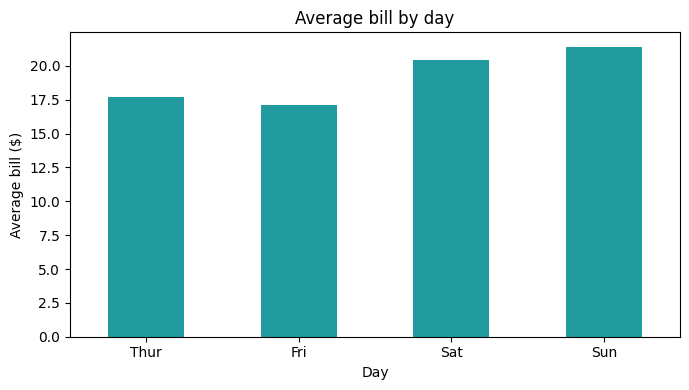

In [4]:
import matplotlib.pyplot as plt

ax = by_day["mean"].plot(kind="bar", color="#219B9D", figsize=(7, 4))
ax.set_title("Average bill by day")
ax.set_xlabel("Day")
ax.set_ylabel("Average bill ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<div dir="rtl">

## 5. مبروك، هذا أول تحليل لك

اقرأ الرسم والجدول معًا، واكتب في قناة فريقك في Slack جملة واحدة مثل:
> «متوسط الفاتورة يوم ... أعلى من ...، وعدد الفواتير يوم ... هو الأكبر، لذلك أقترح ...».

### تحدٍّ صغير (اختياري)
- في الخلية السابقة لـ `by_day`، غيّر `"day"` إلى `"time"` واحذف سطر `.reindex(...)`. ماذا تلاحظ عن الغداء والعشاء؟
- أو اطلب من Gemini داخل Colab: «احسب نسبة البقشيش من الفاتورة لكل يوم وارسمها».

لا تقلق إن لم تفهم كل سطر الآن. في الأسابيع القادمة سنفهم كل خطوة معًا.

</div>

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv")
df.head()